# Unit 11 – Model performance measurement (AUC and R²)
**Part 1** classification: ROC-AUC, precision and recall for a logistic regression and a random forest, changing regularisation, tree depth and class imbalance.
**Part 2** regression: R² and error for polynomial regression and ridge regularisation as complexity and noise change.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, recall_score, r2_score, mean_squared_error, mean_absolute_error
np.random.seed(42)

## Part 1 – classification and AUC

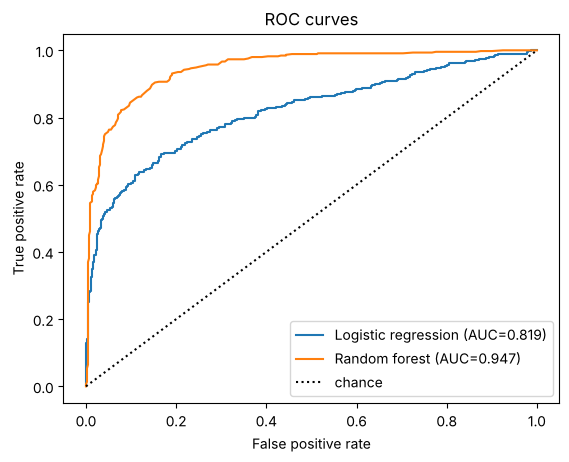

In [2]:
def data(weights=(.5, .5), n_informative=5, flip=0.02, seed=42):
    X, y = make_classification(n_samples=3000, n_features=15, n_informative=n_informative, n_redundant=2,
                               weights=list(weights), flip_y=flip, class_sep=1.0, random_state=seed)
    return train_test_split(X, y, test_size=.3, random_state=seed, stratify=y)

Xtr, Xte, ytr, yte = data()
log = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xtr, ytr)
rf = RandomForestClassifier(n_estimators=200, random_state=0).fit(Xtr, ytr)
for name, mdl in (('Logistic regression', log), ('Random forest', rf)):
    fpr, tpr, _ = roc_curve(yte, mdl.predict_proba(Xte)[:, 1])
    plt.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(yte, mdl.predict_proba(Xte)[:, 1]):.3f})')
plt.plot([0, 1], [0, 1], 'k:', label='chance'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.legend(); plt.title('ROC curves'); plt.show()

In [3]:
rows = []
for C in (0.0001, 0.01, 1, 100):
    m = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=2000)).fit(Xtr, ytr)
    rows.append({'model': 'LogReg', 'parameter': f'C={C}', 'test_AUC': round(roc_auc_score(yte, m.predict_proba(Xte)[:, 1]), 4),
                 'train_AUC': round(roc_auc_score(ytr, m.predict_proba(Xtr)[:, 1]), 4)})
for depth in (1, 2, 4, 8, None):
    m = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=0).fit(Xtr, ytr)
    rows.append({'model': 'RandomForest', 'parameter': f'max_depth={depth}', 'test_AUC': round(roc_auc_score(yte, m.predict_proba(Xte)[:, 1]), 4),
                 'train_AUC': round(roc_auc_score(ytr, m.predict_proba(Xtr)[:, 1]), 4)})
pd.DataFrame(rows)

,model,parameter,test_AUC,train_AUC
0,LogReg,C=0.0001,0.7840,0.7707
1,LogReg,C=0.01,0.8168,0.7992
2,LogReg,C=1,0.8189,0.8002
3,LogReg,C=100,0.8189,0.8002
4,RandomForest,max_depth=1,0.7741,0.7816
5,RandomForest,max_depth=2,0.8171,0.8313
6,RandomForest,max_depth=4,0.8840,0.9147
7,RandomForest,max_depth=8,0.9335,0.9896
8,RandomForest,max_depth=None,0.9468,1.0000


### Class imbalance: accuracy vs AUC vs recall

In [4]:
rows = []
for w in ((.5, .5), (.9, .1), (.98, .02)):
    a, b, c, d = data(weights=w)
    m = RandomForestClassifier(n_estimators=200, random_state=0).fit(a, c)
    pred = m.predict(b)
    rows.append({'class balance': f'{int(w[0]*100)}/{int(w[1]*100)}', 'accuracy': round((pred == d).mean(), 3),
                 'AUC': round(roc_auc_score(d, m.predict_proba(b)[:, 1]), 3),
                 'recall (minority)': round(recall_score(d, pred), 3), 'precision (minority)': round(precision_score(d, pred, zero_division=0), 3)})
pd.DataFrame(rows)

,class balance,accuracy,AUC,recall (minority),precision (minority)
0,50/50,0.873,0.947,0.855,0.887
1,90/10,0.930,0.874,0.406,0.867
2,98/2,0.973,0.790,0.077,1.000


## Part 2 – regression and R²

In [5]:
def reg_data(noise=2.0, n=80, seed=0):
    rng = np.random.RandomState(seed); x = rng.uniform(-3, 3, n)
    y = 0.5 * x ** 3 - 2 * x ** 2 + x + 4 + rng.normal(0, noise, n); return x.reshape(-1, 1), y

rows = []
for noise in (0.5, 3, 10):
    X, y = reg_data(noise); a, b, c, d = train_test_split(X, y, test_size=.3, random_state=1)
    for deg in (1, 3, 10):
        m = make_pipeline(PolynomialFeatures(deg), StandardScaler(), LinearRegression()).fit(a, c)
        rows.append({'noise_sd': noise, 'degree': deg, 'train_R2': round(r2_score(c, m.predict(a)), 3), 'test_R2': round(r2_score(d, m.predict(b)), 3),
                     'test_RMSE': round(mean_squared_error(d, m.predict(b)) ** .5, 2), 'test_MAE': round(mean_absolute_error(d, m.predict(b)), 2)})
pd.DataFrame(rows)

,noise_sd,degree,train_R2,test_R2,test_RMSE,test_MAE
0,0.5,1,0.539,0.696,5.15,4.11
1,0.5,3,0.997,0.997,0.53,0.46
2,0.5,10,0.997,0.996,0.59,0.50
3,3.0,1,0.433,0.663,5.66,4.25
4,3.0,3,0.891,0.892,3.20,2.77
5,3.0,10,0.900,0.867,3.56,3.00
6,10.0,1,0.129,0.304,10.88,9.59
7,10.0,3,0.406,0.331,10.67,9.23
8,10.0,10,0.459,0.173,11.86,10.00


In [6]:
X, y = reg_data(3); a, b, c, d = train_test_split(X, y, test_size=.3, random_state=1)
rows = []
for alpha in (1e-6, 0.01, 1, 10, 100):
    m = make_pipeline(PolynomialFeatures(10), StandardScaler(), Ridge(alpha=alpha)).fit(a, c)
    rows.append({'ridge_alpha': alpha, 'train_R2': round(r2_score(c, m.predict(a)), 3), 'test_R2': round(r2_score(d, m.predict(b)), 3)})
pd.DataFrame(rows)

,ridge_alpha,train_R2,test_R2
0,0.000001,0.900,0.867
1,0.010000,0.899,0.879
2,1.000000,0.888,0.899
3,10.000000,0.867,0.895
4,100.000000,0.734,0.764


## Observations
* **AUC vs complexity:** logistic regression plateaued at AUC 0.819 once regularisation weakened (C ≥ 1). The random forest improved from 0.774 (depth 1) to 0.947 (unlimited depth), while its training AUC reached 1.000 – a widening train/test gap.
* **Class imbalance:** accuracy rose (0.873 → 0.973) as the minority class shrank, but AUC fell (0.947 → 0.790) and minority recall collapsed (0.855 → 0.077). Accuracy flatters imbalanced models.
* **R² and noise:** with noise sd 0.5 a cubic model scored test R² 0.997; at sd 10 it scored 0.331. R² reflects the noise ceiling as well as model quality.
* **Over-fitting:** at noise sd 10 a degree-10 polynomial had train R² 0.459 but test R² 0.173. Ridge regularisation (alpha = 1) lifted test R² for the degree-10 model at sd 3 from 0.867 to 0.899, while alpha = 100 over-regularised it to 0.764.